# Avaliação final no TEST · XGBoost

Esta avaliação compara os dois pipelines XGBoost congelados depois da seleção no TRAIN. O modelo completo é a versão 1 do Model Registry. O modelo reduzido vem do run de quatro features. Ambos aplicam argmax e são avaliados nos mesmos exames reservados.

O notebook lê os resultados agregados de `python -m saude_fetal.evaluate_test`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
report = ROOT / "reports" / "test" / "xgboost_full_vs_reduced_v1"
manifest = json.loads((report / "manifest.json").read_text(encoding="utf-8"))
metrics = pd.read_csv(report / "metrics" / "test_model_metrics.csv").set_index("model")
by_class = pd.read_csv(report / "metrics" / "test_class_metrics.csv")
print(f"{manifest['n_test']} exames no TEST · {manifest['n_pathological']} patológicos")
display(pd.DataFrame(manifest["models"])[["model", "model_uri"]])

def show_figure(filename):
    display(Image(filename=str(report / "figures" / filename)))

426 exames no TEST · 35 patológicos


,model,model_uri
0,XGBoost · 21 features,models:/saude-fetal-xgboost/1
1,XGBoost · 4 features,runs:/029dd288f1284c45ab54708dcf94a3e2/model


## Resultados no TEST

As métricas macro dão o mesmo peso a cada classe. A precisão patológica mede a fração de casos realmente patológicos entre as previsões dessa classe. O recall usa como denominador todos os casos patológicos.

,F1 macro,Acurácia,Recall macro,Precision macro,Recall patológico,Precisão patológica
model,,,,,,
XGBoost · 21 features,89.1%,94.1%,87.5%,91.3%,91.4%,88.9%
XGBoost · 4 features,48.8%,78.9%,46.4%,56.8%,14.3%,41.7%


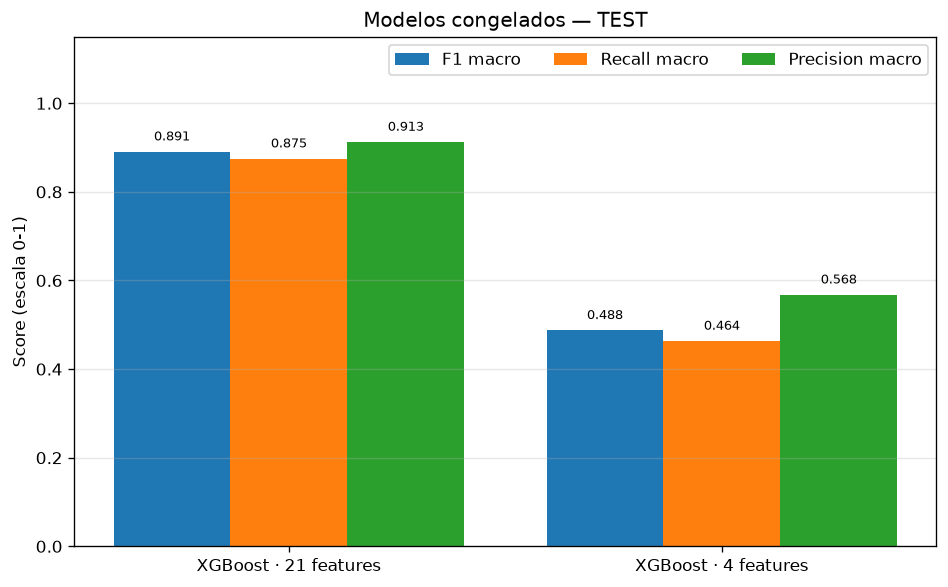

Diferença de F1 macro entre 21 e 4 features no TEST · **+40.3 p.p.**

In [2]:
columns = {
    "f1_macro": "F1 macro",
    "accuracy": "Acurácia",
    "recall_macro": "Recall macro",
    "precision_macro": "Precision macro",
    "recall_patologico": "Recall patológico",
    "precision_patologico": "Precisão patológica",
}
display(metrics[list(columns)].rename(columns=columns).style.format("{:.1%}"))
show_figure("macro_comparison.png")
delta = 100 * metrics["f1_macro"].diff(-1).iloc[0]
display(Markdown(f"Diferença de F1 macro entre 21 e 4 features no TEST · **{delta:+.1f} p.p.**"))

## Erros por classe

As matrizes exibem contagens e proporções normalizadas pela classe real. Na tabela de contagens patológicas, o falso negativo é um caso Patológico previsto como Normal ou Suspeito.

,Patológicos detectados,Patológicos perdidos,Falsos alertas patológicos,Demais sem alerta patológico
model,,,,
XGBoost · 21 features,32,3,4,387
XGBoost · 4 features,5,30,7,384


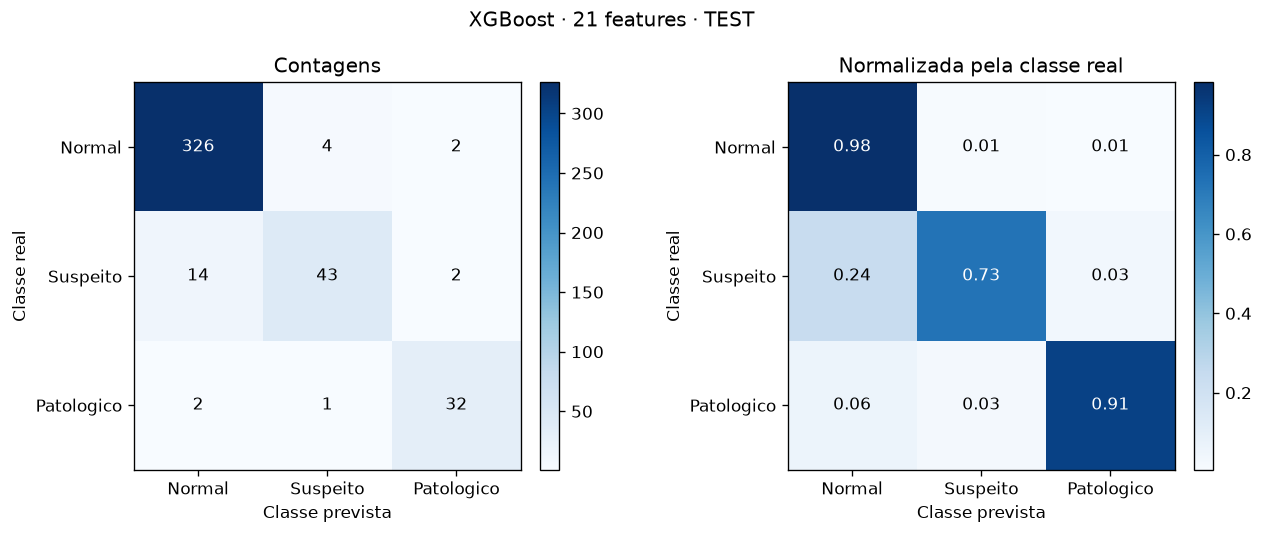

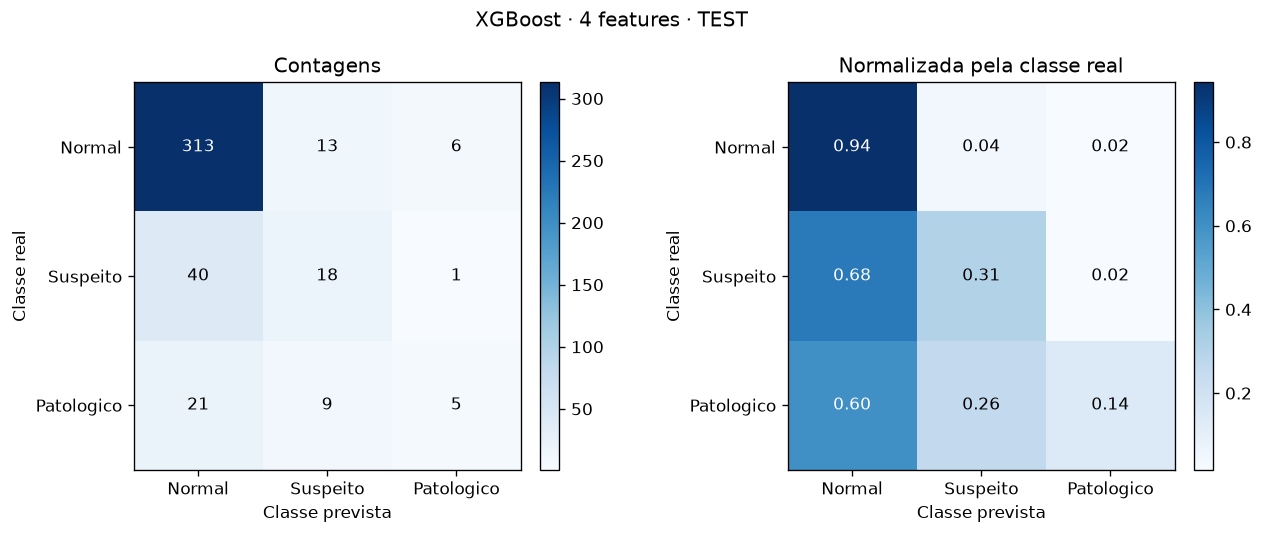

In [3]:
counts = {
    "tp_patologico": "Patológicos detectados",
    "fn_patologico": "Patológicos perdidos",
    "fp_patologico": "Falsos alertas patológicos",
    "tn_patologico": "Demais sem alerta patológico",
}
display(metrics[list(counts)].rename(columns=counts))
display(by_class.set_index(["model", "classe"]).style.format(
    {"precision": "{:.1%}", "recall": "{:.1%}", "f1-score": "{:.1%}", "support": "{:.0f}"}
))
show_figure("confusion_full.png")
show_figure("confusion_reduced.png")

## Ordenação dos scores patológicos

As curvas comparam Patológico contra as demais classes. A linha de referência na precision–recall corresponde à prevalência de Patológico no TEST.

,test_ap_patologico,test_roc_auc_patologico,test_log_loss
model,,,
XGBoost · 21 features,0.881,0.989,0.207
XGBoost · 4 features,0.300,0.802,0.545


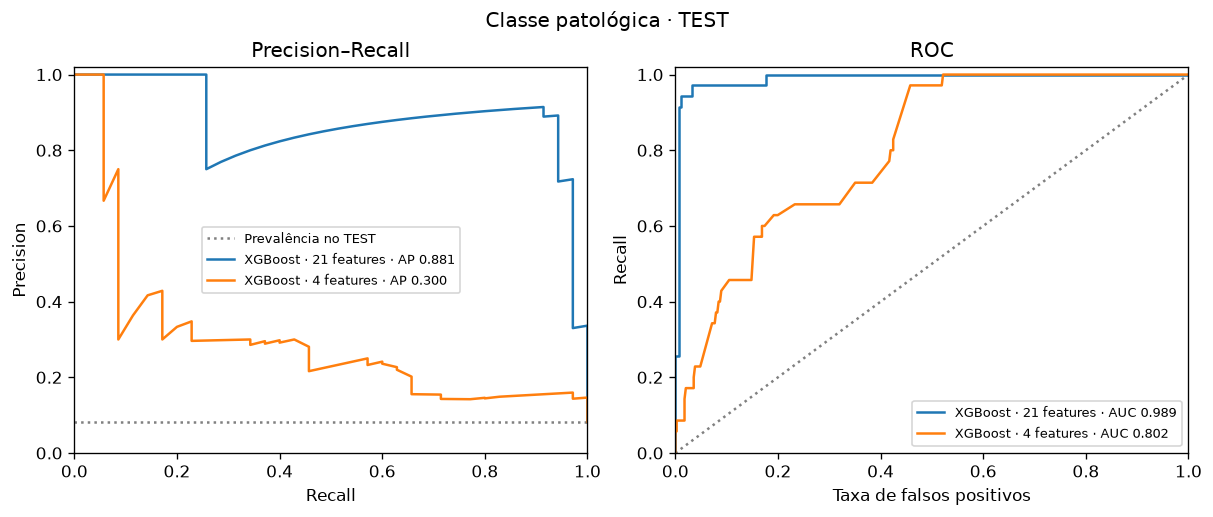

In [4]:
display(metrics[["test_ap_patologico", "test_roc_auc_patologico", "test_log_loss"]].round(3))
show_figure("critical_pr_roc.png")

## Limites da comparação

Os resultados descrevem dois pipelines já ajustados, com hiperparâmetros selecionados, representações de features e protocolos de validação diferentes. A diferença observada combina essas escolhas com a quantidade de features. Os dados disponíveis não identificam pacientes. Como este TEST foi consultado nesta avaliação, qualquer ajuste posterior orientado por ele exige outra amostra reservada para confirmação independente.